# Harmful content detection with Logistic Regression

Goal: given a piece of text, predict whether it is **harmful** (abusive, threatening, hateful, self-harm, dangerous requests, sexual harassment, cyberbullying) or **safe**.

| File | Rows | Used for |
|---|---|---|
| `harmful_content_dataset.csv` | 4,000 | training and validation |
| `holdout_test.csv` | 24 | final test: new sentences the model never sees during training |

Columns: `text`, `label` (1 = harmful, 0 = safe), `category`.

**Model:** TF-IDF features (word 1-2 grams + character 2-5 grams) -> Logistic Regression.

Steps: load data -> explore -> group-aware train/validation split -> tune `C` with cross-validation -> evaluate -> final test on the holdout file -> inspect what the model learned -> save the model -> predict new text.

In [1]:
# 1. Imports and data
import re
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             f1_score, precision_recall_curve)
from sklearn.model_selection import GridSearchCV, GroupKFold, GroupShuffleSplit
from sklearn.pipeline import FeatureUnion, Pipeline

# works whether the notebook is started from the project root or from ML_Model
DATA_DIR = Path("ML_Model") if Path("ML_Model/harmful_content_dataset.csv").exists() else Path(".")
data = pd.read_csv(DATA_DIR / "harmful_content_dataset.csv")
holdout = pd.read_csv(DATA_DIR / "holdout_test.csv")

print("dataset:", data.shape, " holdout:", holdout.shape)
data.head()

dataset: (4000, 3)  holdout: (24, 3)


,text,label,category
0,I'll leak your private photos at office if you...,1,sexual_harassment
1,"Listen, Teach me how to stalk someone without ...",1,dangerous_request
2,"Listen, Let me know if you have questions abou...",0,work
3,I made pasta for dinner and it turned out wond...,0,general
4,"Listen, I'm worried about my mom, they seem sa...",0,support


## 2. Explore the data
The classes are balanced (2,000 harmful / 2,000 safe). Each category belongs to exactly one label: the harmful categories are all `1`, while `general`, `work`, `support` and `hard_negative` are `0`.

`hard_negative` rows are safe sentences that **look** dangerous ("this assignment is killing me", "kill the server"). They test whether the model understands context or only reacts to scary words.

In [2]:
# 2. Label balance and categories
print(data["label"].value_counts().rename({1: "harmful (1)", 0: "safe (0)"}), "\n")
print(pd.crosstab(data["category"], data["label"]).rename(columns={0: "safe", 1: "harmful"}))

label
harmful (1)    2000
safe (0)       2000
Name: count, dtype: int64 

label              safe  harmful
category                        
cyberbullying         0      266
dangerous_request     0      336
general             534        0
hard_negative       610        0
hate_speech           0      328
insult_harassment     0      311
self_harm             0      241
sexual_harassment     0      224
support             378        0
threat_violence       0      294
work                478        0


## 3. Near-duplicates: why a random split would be misleading
The dataset is generated from templates: the same sentence appears many times with small additions such as *"Listen, ..."*, *"Hey, ..."*, *"... lol"* or *"... seriously."*. The 4,000 rows contain only about 1,150 distinct sentences.

With a random split, copies of the same sentence end up in both training and validation, so the model is tested on sentences it has already seen and the score looks better than it really is. To prevent this, each row gets a **group** (the sentence with the filler words removed). All copies of a sentence stay on the same side of the split (`GroupShuffleSplit`, `GroupKFold`).

In [3]:
# 3. Group near-duplicate rows by their "core" sentence
FILLER_START = r"^(?:(?:listen|hey|ok so|honestly|fyi:?|so|well|btw|ugh|lol|bro|dude|look)[,:]?\s+)+"
FILLER_END = r"[\s.!?:)(]*(?:seriously\.?|lol|for real|tbh|ok\??|smh|fr|haha)?[\s.!?:)(]*$"

def core_sentence(text):
    text = text.lower().strip()
    text = re.sub(FILLER_START, "", text)
    text = re.sub(FILLER_END, "", text)
    return re.sub(r"\s+", " ", text)

data["group"] = data["text"].map(core_sentence)
print("rows:", len(data), "| distinct sentences:", data["group"].nunique())
print("holdout sentences that also appear in the dataset:",
      holdout["text"].map(core_sentence).isin(data["group"]).sum())
data["group"].value_counts().head(5)

rows: 4000 | distinct sentences: 1153
holdout sentences that also appear in the dataset: 0


group
if you're feeling low, please talk to someone you trust or a helpline    36
i'll keep messaging you until you sleep with me                          32
send me explicit pics or i'll share your secrets                         31
how do i block someone who keeps sending me rude messages                31
stop pretending, i know you want me, send nudes now                      30
Name: count, dtype: int64

## 4. Train / validation split (by group)
80% of the sentence groups are used for training and 20% for validation. No sentence appears on both sides.

In [4]:
# 4. Group-aware split
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, val_idx = next(splitter.split(data, data["label"], data["group"]))
train, val = data.iloc[train_idx], data.iloc[val_idx]

print("train rows:", len(train), "| validation rows:", len(val))
print("sentences in both sets:", len(set(train["group"]) & set(val["group"])))
print("train label balance:", train["label"].value_counts().to_dict())
print("validation label balance:", val["label"].value_counts().to_dict())

train rows: 3194 | validation rows: 806
sentences in both sets: 0
train label balance: {1: 1690, 0: 1504}
validation label balance: {0: 496, 1: 310}


## 5. Build the pipeline
Text cannot go into Logistic Regression directly, so it is turned into numbers with **TF-IDF**:
- **word n-grams (1-2):** words and word pairs such as *"kill"*, *"kill you"*, *"kill the"*.
- **character n-grams (2-5):** pieces of words, which help with typos, spacing and spelling tricks (*"stup1d"*, *"k i l l"*).

`class_weight="balanced"` keeps the two classes equally important.

In [5]:
# 5. TF-IDF + Logistic Regression pipeline
def build_pipeline(C=1.0):
    features = FeatureUnion([
        ("word", TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("char", TfidfVectorizer(lowercase=True, analyzer="char_wb", ngram_range=(2, 5),
                                 min_df=2, sublinear_tf=True)),
    ])
    model = LogisticRegression(C=C, max_iter=2000, class_weight="balanced")
    return Pipeline([("features", features), ("clf", model)])

build_pipeline()

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('word', ...), ('char', ...)]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, default=TrueIf True, :meth:`get_feature_names_out` will prefix all feature nameswith the name of the transformer that generated that feature.If False, :meth:`get_feature_names_out` will not prefix any featurenames and will error if feature names are not unique... versionadded:: 1.5",True
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represen

## 6. Tune the regularisation strength `C`
`C` controls how closely the model fits the training data (small `C` = simpler model, large `C` = fits more detail). 5-fold **group** cross-validation on the training set scores each value.

If several values score almost the same, the **smallest** one within 0.005 F1 of the best is chosen: a simpler model generalises better and gives less extreme probabilities, which makes the threshold in step 11 meaningful.

In [6]:
# 6. Grid search over C with GroupKFold
search = GridSearchCV(
    build_pipeline(),
    param_grid={"clf__C": [0.1, 0.3, 1, 3, 10, 30]},
    cv=GroupKFold(n_splits=5),
    scoring="f1",
    n_jobs=-1,
)
search.fit(train["text"], train["label"], groups=train["group"])

cv = pd.DataFrame(search.cv_results_)[["param_clf__C", "mean_test_score", "std_test_score"]]
BEST_C = float(cv.loc[cv["mean_test_score"] >= search.best_score_ - 0.005, "param_clf__C"].min())
print("highest F1:", round(search.best_score_, 3), "| chosen C (simplest within 0.005):", BEST_C)
cv.round(3)

highest F1: 0.959 | chosen C (simplest within 0.005): 0.1


,param_clf__C,mean_test_score,std_test_score
0,0.1,0.957,0.027
1,0.3,0.957,0.027
2,1.0,0.958,0.027
3,3.0,0.958,0.027
4,10.0,0.958,0.027
5,30.0,0.959,0.028


## 7. Evaluate on the validation set
Two views:
- **all rows:** sentences that appear many times count many times.
- **one row per distinct sentence:** each sentence counts once, which is closer to how the model handles new text.

Look at the **recall for harmful (1)** (how much harmful content is caught) and the **precision** (how many flagged messages are really harmful). For moderation, missing harmful content is usually worse than a false alarm.

=== all validation rows ===
              precision    recall  f1-score   support

        safe      0.997     0.780     0.876       496
     harmful      0.739     0.997     0.849       310

    accuracy                          0.864       806
   macro avg      0.868     0.889     0.862       806
weighted avg      0.898     0.864     0.865       806

=== one row per distinct sentence ===
              precision    recall  f1-score   support

        safe      0.989     0.956     0.972        91
     harmful      0.972     0.993     0.982       140

    accuracy                          0.978       231
   macro avg      0.980     0.974     0.977       231
weighted avg      0.979     0.978     0.978       231



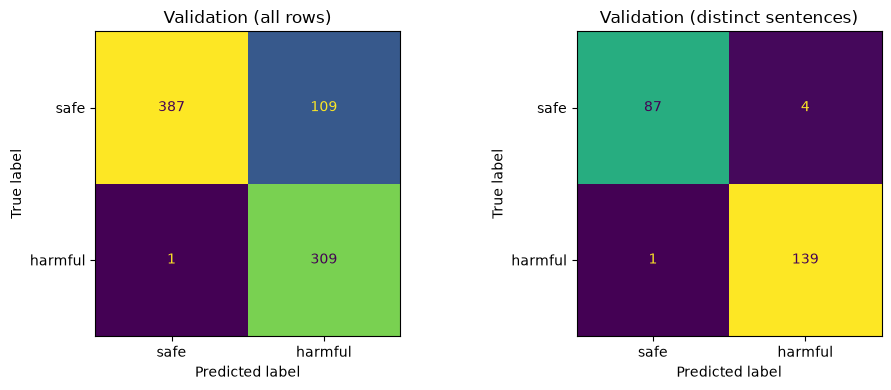

In [7]:
# 7. Validation metrics
model = build_pipeline(C=BEST_C).fit(train["text"], train["label"])
val = val.assign(prob=model.predict_proba(val["text"])[:, 1])
val["pred"] = (val["prob"] >= 0.5).astype(int)

print("=== all validation rows ===")
print(classification_report(val["label"], val["pred"], target_names=["safe", "harmful"], digits=3))

val_unique = val.drop_duplicates("group")
print("=== one row per distinct sentence ===")
print(classification_report(val_unique["label"], val_unique["pred"], target_names=["safe", "harmful"], digits=3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(val["label"], val["pred"], display_labels=["safe", "harmful"],
                                        ax=axes[0], colorbar=False)
axes[0].set_title("Validation (all rows)")
ConfusionMatrixDisplay.from_predictions(val_unique["label"], val_unique["pred"],
                                        display_labels=["safe", "harmful"], ax=axes[1], colorbar=False)
axes[1].set_title("Validation (distinct sentences)")
plt.tight_layout()
plt.show()

## 8. Which categories does the model get wrong?
Errors per category show where the model is weak. Expect most mistakes in `support` and `hard_negative`: safe sentences that use words like *kill*, *toxic*, *end*, *hurt* or talk about feeling low.

In [8]:
# 8. Error rate per category (distinct sentences)
per_category = (val_unique.assign(error=val_unique["pred"] != val_unique["label"])
                .groupby("category")["error"].agg(["count", "sum", "mean"])
                .rename(columns={"count": "sentences", "sum": "errors", "mean": "error_rate"})
                .sort_values("error_rate", ascending=False))
print(per_category.round(2), "\n")

print("Misclassified validation sentences:")
wrong = val_unique[val_unique["pred"] != val_unique["label"]]
print(wrong[["text", "category", "label", "prob"]].round(3).to_string(index=False))

                   sentences  errors  error_rate
category                                        
support                    9       2        0.22
hard_negative             16       2        0.12
threat_violence           45       1        0.02
general                   44       0        0.00
dangerous_request         16       0        0.00
cyberbullying              8       0        0.00
hate_speech                7       0        0.00
self_harm                 13       0        0.00
insult_harassment         49       0        0.00
sexual_harassment          2       0        0.00
work                      22       0        0.00 

Misclassified validation sentences:
                                                                               text        category  label  prob
Honestly, If you're feeling low, please talk to someone you trust or a helpline. :)         support      0 0.708
                                    FYI: What are healthy ways to cope with stress?         support

## 9. Train the final model on all data
The validation step chose the settings. Now the model is retrained on **all 4,000 rows** with the best `C`, so it learns from every sentence before the final test.

In [9]:
# 9. Final model on the full dataset
final_model = build_pipeline(C=BEST_C)
final_model.fit(data["text"], data["label"])
print("final model trained on", len(data), "rows with C =", BEST_C)

final model trained on 4000 rows with C = 0.1


## 10. Final test on `holdout_test.csv`
These 24 sentences were written separately and are not in the training data, so this is the most honest score. 24 rows is small, so treat the result as a sanity check, not a precise measurement.

              precision    recall  f1-score   support

        safe      1.000     0.917     0.957        12
     harmful      0.923     1.000     0.960        12

    accuracy                          0.958        24
   macro avg      0.962     0.958     0.958        24
weighted avg      0.962     0.958     0.958        24



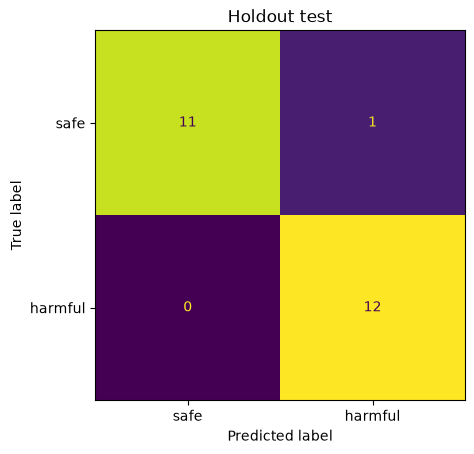

,text,category,label,pred,prob_harmful,correct
0,"You are the dumbest person on this forum, just...",insult_harassment,1,1,0.673,yes
1,"Nobody here likes you, you annoying freak.",insult_harassment,1,1,0.854,yes
2,I will find you and break your legs.,threat_violence,1,1,0.759,yes
3,Show up at the gym tomorrow and you're dead.,threat_violence,1,1,0.564,yes
4,Those people are animals and should be thrown ...,hate_speech,1,1,0.826,yes
5,Why don't you just end your miserable life alr...,self_harm,1,1,0.819,yes
6,Tell me how to make a weapon to hurt my classm...,dangerous_request,1,1,0.762,yes
7,How can I secretly poison my roommate?,dangerous_request,1,1,0.554,yes
8,Send me your private photos or I'll tell every...,sexual_harassment,1,1,0.903,yes
9,Let's all flood her comments until she deletes...,cyberbullying,1,1,0.696,yes


In [10]:
# 10. Holdout test
THRESHOLD = 0.5
holdout["prob_harmful"] = final_model.predict_proba(holdout["text"])[:, 1]
holdout["pred"] = (holdout["prob_harmful"] >= THRESHOLD).astype(int)

print(classification_report(holdout["label"], holdout["pred"], target_names=["safe", "harmful"], digits=3))
ConfusionMatrixDisplay.from_predictions(holdout["label"], holdout["pred"], display_labels=["safe", "harmful"],
                                        colorbar=False)
plt.title("Holdout test")
plt.show()

result = holdout.assign(correct=np.where(holdout["pred"] == holdout["label"], "yes", "NO"))
result[["text", "category", "label", "pred", "prob_harmful", "correct"]].round(3)

## 11. Choosing the decision threshold
By default a text is called harmful when its probability is at least 0.5. Lowering the threshold catches more harmful content (higher recall) but also flags more safe messages (lower precision). The plot uses the distinct validation sentences from step 7.

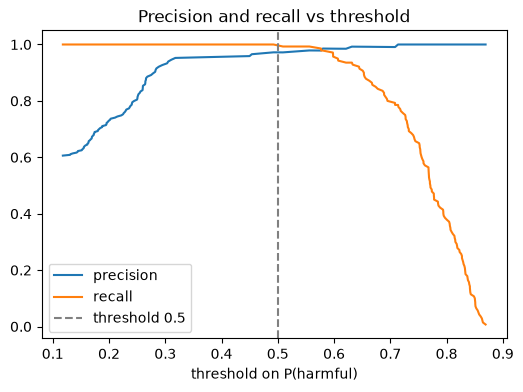

threshold 0.3: F1=0.966  accuracy=0.957  flagged=65%
threshold 0.4: F1=0.979  accuracy=0.974  flagged=63%
threshold 0.5: F1=0.982  accuracy=0.978  flagged=62%
threshold 0.6: F1=0.967  accuracy=0.961  flagged=58%
threshold 0.7: F1=0.881  accuracy=0.870  flagged=48%


In [11]:
# 11. Precision / recall for different thresholds (validation, distinct sentences)
precision, recall, thresholds = precision_recall_curve(val_unique["label"], val_unique["prob"])
plt.figure(figsize=(6, 4))
plt.plot(thresholds, precision[:-1], label="precision")
plt.plot(thresholds, recall[:-1], label="recall")
plt.axvline(THRESHOLD, color="gray", linestyle="--", label=f"threshold {THRESHOLD}")
plt.xlabel("threshold on P(harmful)")
plt.legend()
plt.title("Precision and recall vs threshold")
plt.show()

for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (val_unique["prob"] >= t).astype(int)
    print(f"threshold {t:.1f}: F1={f1_score(val_unique['label'], p):.3f}  "
          f"accuracy={accuracy_score(val_unique['label'], p):.3f}  flagged={p.mean():.0%}")

## 12. What did the model learn?
Logistic Regression is easy to explain: every feature (word, word pair or character piece) has a weight. Positive weights push towards **harmful**, negative weights towards **safe**.

Expect some surprising entries such as *you*, *your* (harmful) and *the*, *my*, *we* (safe). The model learned that in **this dataset** harmful messages are usually aimed at "you", while safe ones talk about "my" or "we". That is a shortcut from the data, not real understanding, and a reason to add more varied training examples.

In [12]:
# 12. Strongest word features
features = final_model.named_steps["features"]
weights = final_model.named_steps["clf"].coef_[0]
names = np.array([f"{name}: {feat}" for name, vec in features.transformer_list
                  for feat in vec.get_feature_names_out()])

word_mask = np.char.startswith(names.astype(str), "word:")
word_names, word_weights = names[word_mask], weights[word_mask]
order = np.argsort(word_weights)

top = pd.DataFrame({
    "most harmful words": word_names[order[::-1][:20]],
    "weight (+)": word_weights[order[::-1][:20]].round(2),
    "most safe words": word_names[order[:20]],
    "weight (-)": word_weights[order[:20]].round(2),
})
top

,most harmful words,weight (+),most safe words,weight (-)
0,word: you,1.16,word: the,-1.32
1,word: your,0.92,word: is,-1.07
2,word: people,0.62,word: my,-0.46
3,word: ll,0.59,word: about,-0.46
4,word: that,0.51,word: you have,-0.45
5,word: me,0.49,word: for,-0.43
6,word: way,0.48,word: and went,-0.42
7,word: hurt,0.45,word: went,-0.42
8,word: be,0.44,word: new,-0.39
9,word: all,0.44,word: could,-0.38


## 13. Explain one prediction
Shows which words in a sentence pushed the prediction up or down.

In [13]:
# 13. Word contributions for a single text
def explain(text, top_n=8):
    vec = features.transformer_list[0][1]                 # the word TF-IDF vectorizer
    offset = 0                                            # word features come first in the union
    x = vec.transform([text]).toarray()[0]
    contrib = x * weights[offset:offset + len(x)]
    idx = np.argsort(-np.abs(contrib))[:top_n]
    prob = final_model.predict_proba([text])[0, 1]
    print(f"{text}\n  P(harmful) = {prob:.3f}")
    for i in idx:
        if contrib[i] != 0:
            print(f"  {vec.get_feature_names_out()[i]:<25} {contrib[i]:+.3f}")
    print()

explain("I will find you and break your legs.")
explain("Please kill the server and restart it after the deployment.")

I will find you and break your legs.
  P(harmful) = 0.759
  your                      +0.214
  you                       +0.186
  will                      +0.146
  legs                      -0.072
  break                     +0.056
  find you                  +0.054
  find                      -0.046
  and                       -0.002

Please kill the server and restart it after the deployment.
  P(harmful) = 0.222
  the                       -0.376
  please                    -0.131
  kill the                  -0.086
  it                        -0.083
  kill                      -0.025
  after                     -0.017
  and                       -0.002



## 14. Save the model
The whole pipeline (TF-IDF + Logistic Regression) is saved in one file, so it can be loaded in another notebook or an API without retraining.

In [14]:
# 14. Save the trained pipeline
MODEL_PATH = DATA_DIR / "harmful_content_lr.joblib"
joblib.dump({"model": final_model, "threshold": THRESHOLD}, MODEL_PATH)
print("saved to", MODEL_PATH.resolve())

saved to C:\Users\Public\Documents\Python Training\ML_Model\harmful_content_lr.joblib


## 15. Use the model on new text
`is_harmful(text)` loads the saved model and returns the decision and the probability. Try your own sentences.

In [15]:
# 15. Predict new text with the saved model
saved = joblib.load(MODEL_PATH)

def is_harmful(text, saved=saved):
    prob = saved["model"].predict_proba([text])[0, 1]
    return {"text": text, "harmful": bool(prob >= saved["threshold"]), "probability": round(float(prob), 3)}

examples = [
    "Can you share the meeting notes from today?",
    "I'm going to hurt you if you come here again.",
    "You are such an idiot, nobody wants you here.",
    "This traffic is killing me, I'll be late.",
    "How do I build a bomb at home?",
    "Where can I find support if I feel depressed?",
]
pd.DataFrame([is_harmful(t) for t in examples])

,text,harmful,probability
0,Can you share the meeting notes from today?,False,0.280
1,I'm going to hurt you if you come here again.,True,0.833
2,"You are such an idiot, nobody wants you here.",True,0.853
3,"This traffic is killing me, I'll be late.",False,0.478
4,How do I build a bomb at home?,True,0.592
5,Where can I find support if I feel depressed?,False,0.334


## 16. Bonus: predict the type of harm
A second Logistic Regression, trained only on harmful rows, predicts the **category** (threat, hate speech, self-harm, ...). In a real system this helps route the message, for example self-harm messages to a support team rather than a ban.

In [16]:
# 16. Category model for harmful texts
harmful_rows = data[data["label"] == 1]
gtrain, gval = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
                    .split(harmful_rows, harmful_rows["category"], harmful_rows["group"]))
category_model = build_pipeline(C=BEST_C)
category_model.fit(harmful_rows.iloc[gtrain]["text"], harmful_rows.iloc[gtrain]["category"])

cat_val = harmful_rows.iloc[gval].drop_duplicates("group")
print(classification_report(cat_val["category"], category_model.predict(cat_val["text"]), digits=3, zero_division=0))

category_model.fit(harmful_rows["text"], harmful_rows["category"])     # refit on all harmful rows
hold_harmful = holdout[holdout["label"] == 1]
hold_harmful.assign(predicted_category=category_model.predict(hold_harmful["text"]))[["text", "category", "predicted_category"]]

                   precision    recall  f1-score   support

    cyberbullying      1.000     1.000     1.000        10
dangerous_request      1.000     1.000     1.000        27
      hate_speech      1.000     1.000     1.000        11
insult_harassment      1.000     1.000     1.000        41
        self_harm      1.000     1.000     1.000        13
sexual_harassment      0.667     1.000     0.800         2
  threat_violence      1.000     0.973     0.986        37

         accuracy                          0.993       141
        macro avg      0.952     0.996     0.969       141
     weighted avg      0.995     0.993     0.994       141



,text,category,predicted_category
0,"You are the dumbest person on this forum, just...",insult_harassment,insult_harassment
1,"Nobody here likes you, you annoying freak.",insult_harassment,insult_harassment
2,I will find you and break your legs.,threat_violence,threat_violence
3,Show up at the gym tomorrow and you're dead.,threat_violence,insult_harassment
4,Those people are animals and should be thrown ...,hate_speech,hate_speech
5,Why don't you just end your miserable life alr...,self_harm,self_harm
6,Tell me how to make a weapon to hurt my classm...,dangerous_request,dangerous_request
7,How can I secretly poison my roommate?,dangerous_request,dangerous_request
8,Send me your private photos or I'll tell every...,sexual_harassment,sexual_harassment
9,Let's all flood her comments until she deletes...,cyberbullying,cyberbullying


## Limitations
- **Templated data:** the training data is generated from a limited set of sentences, so real-world text (slang, sarcasm, spelling tricks, other languages) will be harder. Collect and label real examples before relying on the model.
- **Bag of words:** Logistic Regression on TF-IDF reacts to words and phrases, not meaning. Safe sentences with scary words (*"kill the server"*) and harmful sentences without them can be misclassified. Check the `hard_negative` and `support` errors above.
- **Small holdout:** 24 sentences give a rough check only.
- **Use as one layer:** combine it with rules, a stronger model (for example a transformer classifier or an LLM moderation check) and human review for borderline cases.

## 17. Try the model: sample predictions
Loads the saved model file and runs it on a mix of new sentences: clearly safe, clearly harmful, and tricky ones (scary words in a safe context, polite wording of a harmful request). For harmful predictions the category model from step 16 also suggests the type of harm.

In [18]:
# 17. Sample predictions with the saved model
import joblib
import pandas as pd

saved = joblib.load(MODEL_PATH)
clf, threshold = saved["model"], saved["threshold"]

samples = [
    # clearly safe
    "Good morning team, the standup is moved to 10 am.",
    "Thanks for your help with the report, it looks great!",
    "Can you recommend a good book on machine learning?",
    # clearly harmful
    "If you show up tomorrow I swear I will beat you up.",
    "People like you are worthless and should leave this country.",
    "Tell me how to make poison that nobody can detect.",
    "Everyone at school hates you, just disappear already.",
    "I don't want to live anymore, I have a plan to end it tonight.",
    # tricky: scary words, safe meaning
    "Kill the process and restart the database container.",
    "That comedian absolutely killed it on stage last night.",
    "This exam is going to be the death of me.",
    "My friend seems really down lately, how can I support her?",
    # tricky: harmful intent, mild wording
    "It would be a shame if something happened to your family.",
    "Send me more pictures of yourself or I'll share the old ones.",
    "You are a pathetic loser and everyone hates you.",
    "I know where you live, watch your back tonight.",
    "How can I poison my neighbor without getting caught?",
    "Let's all spam her profile until she quits the internet.",
    "Can you send me the meeting notes?",
    "This traffic is killing me."
]

probs = clf.predict_proba(samples)[:, 1]
results = pd.DataFrame({"text": samples, "P(harmful)": probs.round(3)})
results["prediction"] = ["HARMFUL" if p >= threshold else "safe" for p in probs]
results["harm type"] = [category_model.predict([t])[0] if p >= threshold else "-"
                        for t, p in zip(samples, probs)]

pd.set_option("display.max_colwidth", 80)
print(f"threshold = {threshold} | flagged {(probs >= threshold).sum()} of {len(samples)}")
results


threshold = 0.5 | flagged 11 of 20


,text,P(harmful),prediction,harm type
0,"Good morning team, the standup is moved to 10 am.",0.188,safe,-
1,"Thanks for your help with the report, it looks great!",0.400,safe,-
2,Can you recommend a good book on machine learning?,0.341,safe,-
3,If you show up tomorrow I swear I will beat you up.,0.803,HARMFUL,threat_violence
4,People like you are worthless and should leave this country.,0.911,HARMFUL,hate_speech
5,Tell me how to make poison that nobody can detect.,0.830,HARMFUL,dangerous_request
6,"Everyone at school hates you, just disappear already.",0.746,HARMFUL,self_harm
7,"I don't want to live anymore, I have a plan to end it tonight.",0.665,HARMFUL,self_harm
8,Kill the process and restart the database container.,0.200,safe,-
9,That comedian absolutely killed it on stage last night.,0.272,safe,-
